# Modelos de clasificación para detección temprana de fraude en entidades bancarias
## Notebook 01 — Exploración, limpieza e ingeniería de variables

**Competencia Kaggle:** *Modelos de Fraude 2026* · **Métrica:** área bajo la curva ROC (AUC)

Este notebook sigue la metodología de los códigos de clase (*Ingeniería de variables + Regresión Logística / Random Forest / XGBoost / Ensambles*):

1. Carga de datos de entrenamiento y prueba
2. Datos faltantes, formatos e imputación
3. Análisis descriptivo (boxplots, tasas de fraude, prueba chi cuadrado)
4. Ingeniería de variables cuantitativas: **cuadrados, interacciones y razones** (filtro con prueba de **Kruskal-Wallis**)
5. Ingeniería de variables categóricas: **interacciones categóricas** (prueba **chi cuadrado**) e **interacción cuantitativa × categórica** (Kruskal)
6. **Selección de variables con XGBoost**: las 3 más importantes de cada grupo
7. Construcción de la **base de modelamiento** (train y test) con `LabelEncoder`, que usarán los notebooks 02–05

> El resultado de este notebook son dos archivos (`base_modelo_train.parquet` y `base_modelo_test.parquet`) que leen los notebooks de modelos, para no repetir la ingeniería de variables en cada uno.

## 0. Librerías y configuración

In [1]:
import os, sys, json, time
import warnings
warnings.filterwarnings("ignore")

import pandas as pd # bases de datos
import numpy as np # operaciones vectoriales
import seaborn as sns # gráficos
import matplotlib.pyplot as plt # gráficos
from scipy import stats # pruebas de Kruskal y chi cuadrado para selección de variables
from itertools import combinations # combinaciones para interacciones cuantitativas y categóricas
from xgboost import XGBClassifier # selección de variables por importancia
from sklearn.preprocessing import LabelEncoder # tratamiento de categóricas

pd.set_option("display.max_columns", 50)
SEMILLA = 20042021 # semilla para reproducibilidad

### Rutas de datos
El mismo notebook funciona en **Docker/local**, **Google Colab** y **Databricks**: solo se detecta el entorno y se ajusta `DATA_DIR`.

In [2]:
if "google.colab" in sys.modules:                 # Google Colab: subir los csv a /content/data
    DATA_DIR, OUT_DIR = "/content/data/", "/content/artefactos/"
elif "DATABRICKS_RUNTIME_VERSION" in os.environ:   # Databricks: cambiar por la ruta del Volume
    DATA_DIR, OUT_DIR = "/Volumes/main/default/fraude/", "/Volumes/main/default/fraude/artefactos/"
else:
    # Docker / local: busca la carpeta data/ (con train.csv) aquí o en las carpetas de arriba
    carpeta = os.path.abspath(".")
    while not os.path.exists(os.path.join(carpeta, "data", "train.csv")) and carpeta != os.path.dirname(carpeta):
        carpeta = os.path.dirname(carpeta)
    DATA_DIR = os.path.join(carpeta, "data", "")
    OUT_DIR = "./artefactos/"   # aquí se guardan las bases de modelamiento (junto a los notebooks)
os.makedirs(OUT_DIR, exist_ok=True)
DATA_DIR

'/work/s2/metodos_supervisados/data/'

## 1. Carga de datos
Los archivos de la competencia usan `;` como separador.

### Base de entrenamiento (históricos)

In [3]:
base = pd.read_csv(DATA_DIR + "train.csv", sep=";")
base.head(3)

,ID,Num_Tarjetas,Balance_Tj,Total_Transac,Trans_Int,Estado,Genero,Tipo_Tarjeta,Fraude
0,1,1,2000,31,9,Alabama,Male,American Express,0
1,2,1,0,25,0,Alabama,Male,American Express,0
2,3,1,2000,78,3,Alabama,Male,American Express,0


### Base de test (predicción para Kaggle)

In [4]:
prueba = pd.read_csv(DATA_DIR + "test.csv", sep=";")
prueba.head(3)

,ID,Num_Tarjetas,Balance_Tj,Total_Transac,Trans_Int,Estado,Genero,Tipo_Tarjeta
0,9,1,2000,48,0,Alabama,Male,American Express
1,11,1,2000,5,4,Alabama,Male,American Express
2,19,1,541,21,9,Alabama,Male,American Express


In [5]:
print("Entrenamiento:", base.shape)
print("Test:         ", prueba.shape)

Entrenamiento: (848548, 9)
Test:          (200027, 8)


### Diccionario de datos (descripción de la competencia)

| Variable | Descripción | Tipo |
|---|---|---|
| `ID` | Cédula del cliente | Identificador (no se modela) |
| `Num_Tarjetas` | Número de tarjetas del cliente | Cuantitativa discreta |
| `Balance_Tj` | Balance de las tarjetas de crédito | Cuantitativa continua |
| `Total_Transac` | Total de transacciones del cliente a la fecha | Cuantitativa discreta |
| `Trans_Int` | Total de transacciones internacionales a la fecha | Cuantitativa discreta |
| `Estado` | Lugar de residencia del cliente | Categórica nominal |
| `Genero` | Género del cliente | Categórica nominal |
| `Tipo_Tarjeta` | Franquicia de la tarjeta | Categórica nominal |
| **`Fraude`** | **1 = hizo fraude, 0 = no** | **Variable supervisada (Y)** |

## 2. Datos faltantes y formatos

In [6]:
# Entrenamiento
ft = pd.DataFrame(base.isnull().sum()).reset_index()
ft.columns = ["Variable","Faltantes"]
ft["% Faltantes"] = ft["Faltantes"] * 100 / base.shape[0]
formato = pd.DataFrame({'Variable': list(base.columns), 'Formato': base.dtypes.astype(str)})
ft = pd.merge(ft, formato, on=["Variable"], how="left")
ft

,Variable,Faltantes,% Faltantes,Formato
0,ID,0,0.0,int64
1,Num_Tarjetas,0,0.0,int64
2,Balance_Tj,0,0.0,int64
3,Total_Transac,0,0.0,int64
4,Trans_Int,0,0.0,int64
5,Estado,0,0.0,str
6,Genero,0,0.0,str
7,Tipo_Tarjeta,0,0.0,str
8,Fraude,0,0.0,int64


In [7]:
# Test
ft1 = pd.DataFrame(prueba.isnull().sum()).reset_index()
ft1.columns = ["Variable","Faltantes"]
ft1["% Faltantes"] = ft1["Faltantes"] * 100 / prueba.shape[0]
ft1

,Variable,Faltantes,% Faltantes
0,ID,0,0.0
1,Num_Tarjetas,0,0.0
2,Balance_Tj,0,0.0
3,Total_Transac,0,0.0
4,Trans_Int,0,0.0
5,Estado,0,0.0
6,Genero,0,0.0
7,Tipo_Tarjeta,0,0.0


### Imputación de datos faltantes
Mismo criterio de los códigos de clase: **moda** para categóricas y **mediana** para cuantitativas, calculadas **solo con entrenamiento** y aplicadas a ambas bases. En esta competencia no hay faltantes, pero el código queda listo por si llegara a haberlos.

In [8]:
inputacion = ft.loc[ft["% Faltantes"]>0,].copy()
inputacion.index = range(inputacion.shape[0])

for k in range(inputacion.shape[0]):
    var = inputacion.loc[k,"Variable"]
    if base[var].dtype == "object" or str(base[var].dtype).startswith("str"):
        moda = base[var].mode()[0]
        base[var] = base[var].fillna(moda)      # históricos
        prueba[var] = prueba[var].fillna(moda)  # prueba
    else:
        mediana_ = base[var].median()
        base[var] = base[var].fillna(mediana_)      # históricos
        prueba[var] = prueba[var].fillna(mediana_)  # prueba

print("Variables imputadas:", len(inputacion))
print("Faltantes restantes train:", base.isnull().sum().sum(), "| test:", prueba.isnull().sum().sum())

Variables imputadas: 0
Faltantes restantes train: 0 | test: 0


### Clasificación de variables

In [9]:
cuantitativas = [x for x in base.columns if pd.api.types.is_numeric_dtype(base[x]) and x not in ["ID","Fraude"]]
categoricas   = [x for x in base.columns if not pd.api.types.is_numeric_dtype(base[x]) and x not in ["ID","Fraude"]]
print("Cuantitativas:", cuantitativas)
print("Categóricas:  ", categoricas)

Cuantitativas: ['Num_Tarjetas', 'Balance_Tj', 'Total_Transac', 'Trans_Int']
Categóricas:   ['Estado', 'Genero', 'Tipo_Tarjeta']


### Validaciones de calidad

In [10]:
print("IDs duplicados en train:", base["ID"].duplicated().sum())
print("IDs de test que también están en train:", len(set(base["ID"]) & set(prueba["ID"])))
dup = base.drop(columns=["ID"]).duplicated(keep=False)
print(f"Filas con características idénticas (sin ID): {dup.sum():,} ({100*dup.mean():.1f}%)")

# ¿Clientes con las mismas características pero distinta etiqueta? -> ruido irreducible
grupos = base.groupby(cuantitativas + categoricas)["Fraude"].agg(["mean","size"])
conflicto = grupos[(grupos["mean"]>0) & (grupos["mean"]<1)]
print(f"Perfiles idénticos con etiquetas contradictorias: {len(conflicto):,} perfiles, {conflicto['size'].sum():,} filas")

IDs duplicados en train: 0
IDs de test que también están en train: 0
Filas con características idénticas (sin ID): 329,219 (38.8%)
Perfiles idénticos con etiquetas contradictorias: 3,827 perfiles, 27,840 filas


In [11]:
# Las categorías del test deben existir en entrenamiento (si no, el LabelEncoder fallaría)
for k in categoricas:
    nuevas = set(prueba[k].unique()) - set(base[k].unique())
    print(f"{k}: {base[k].nunique()} categorías | nuevas en test: {nuevas if nuevas else 'ninguna'}")

Estado: 51 categorías | nuevas en test: ninguna
Genero: 2 categorías | nuevas en test: ninguna
Tipo_Tarjeta: 4 categorías | nuevas en test: ninguna


## 3. Análisis descriptivo

### Variable supervisada: balance de clases

,Clientes,%
Fraude,,
0,797761,94.01
1,50787,5.99


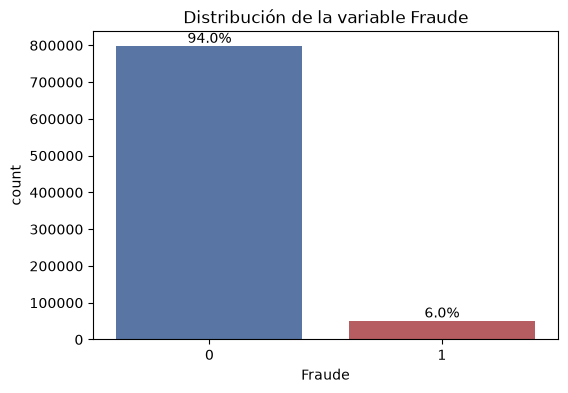

In [12]:
tabla_y = base["Fraude"].value_counts().to_frame("Clientes")
tabla_y["%"] = (100 * tabla_y["Clientes"] / tabla_y["Clientes"].sum()).round(2)
display(tabla_y)

plt.figure(figsize=(6,4))
ax = sns.countplot(x="Fraude", data=base, palette=["#4C72B0","#C44E52"])
for p in ax.patches:
    ax.annotate(f"{100*p.get_height()/len(base):.1f}%", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Distribución de la variable Fraude"); plt.show()

### Descriptivos de las variables cuantitativas

In [13]:
base.get(cuantitativas).describe().round(2)

,Num_Tarjetas,Balance_Tj,Total_Transac,Trans_Int
count,848548.00,848548.00,848548.00,848548.00
mean,1.03,4111.83,28.91,4.04
std,0.17,3997.19,26.56,8.60
min,1.00,0.00,0.00,0.00
25%,1.00,0.00,10.00,0.00
50%,1.00,3714.00,19.00,0.00
75%,1.00,6000.00,39.00,4.00
max,2.00,39725.00,100.00,60.00


In [14]:
# Promedio de cada variable según la clase (perfil del cliente fraudulento vs no fraudulento)
base.groupby("Fraude")[cuantitativas].agg(["mean","median"]).round(2).T

Fraude                      0         1
Num_Tarjetas  mean       1.03      1.04
              median     1.00      1.00
Balance_Tj    mean    3694.14  10672.93
              median  3140.00  10593.00
Total_Transac mean      27.42     52.32
              median    19.00     47.00
Trans_Int     mean       3.96      5.39
              median     0.00      0.00

### Boxplots: logaritmo de cada variable cuantitativa vs Fraude
Se usa una muestra aleatoria de 100 mil registros para que los gráficos sean rápidos (la distribución es la misma).

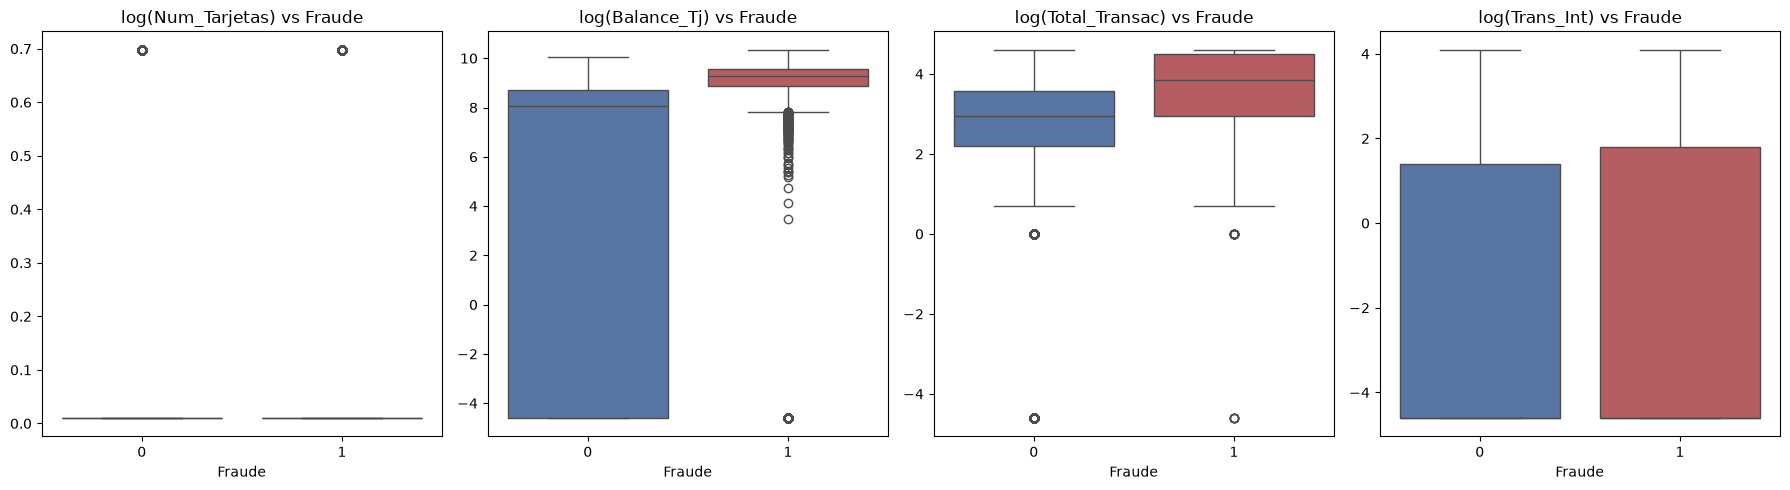

In [15]:
muestra = base.sample(100_000, random_state=SEMILLA)
fig, axes = plt.subplots(1, len(cuantitativas), figsize=(18,5))
for ax, k in zip(axes, cuantitativas):
    sns.boxplot(x="Fraude", y=np.log(muestra[k]+0.01), data=muestra, ax=ax, palette=["#4C72B0","#C44E52"])
    ax.set_title("log(" + k + ") vs Fraude"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### Tasa de fraude por variable categórica

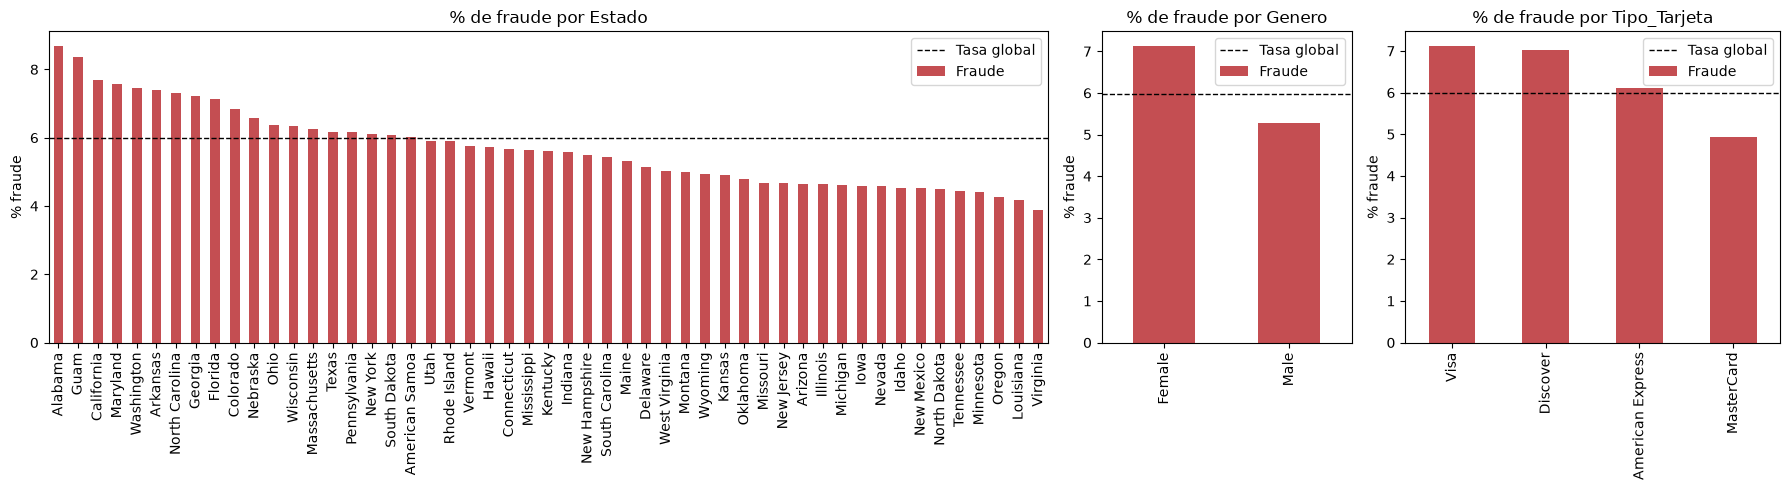

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18,5), gridspec_kw={"width_ratios":[4,1,1.5]})
for ax, k in zip(axes, ["Estado","Genero","Tipo_Tarjeta"]):
    tasa = base.groupby(k)["Fraude"].mean().sort_values(ascending=False) * 100
    tasa.plot(kind="bar", ax=ax, color="#C44E52")
    ax.axhline(100*base["Fraude"].mean(), color="black", ls="--", lw=1, label="Tasa global")
    ax.set_title("% de fraude por " + k); ax.set_ylabel("% fraude"); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); plt.show()

### Prueba chi cuadrado: asociación entre variables categóricas (incluida Fraude)
$H_0$: las variables son independientes. Un p valor ≤ 0.05 indica asociación.

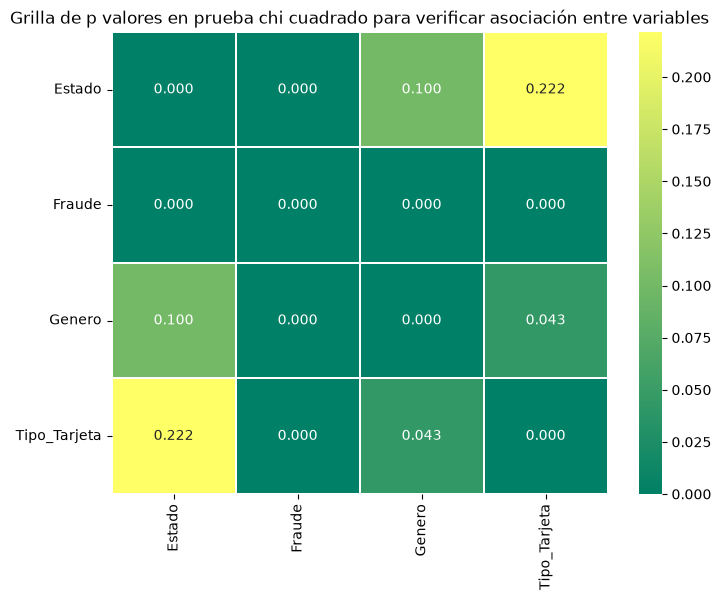

In [17]:
def asociacion(data):
    categoricas_ = list(data.columns)
    grilla = pd.DataFrame([(a,b) for a in categoricas_ for b in categoricas_], columns=["Var1","Var2"])
    grilla["p_value"] = [stats.chi2_contingency(pd.crosstab(data[a], data[b]))[1] for a,b in zip(grilla["Var1"], grilla["Var2"])]
    grilla2 = grilla.pivot(index="Var1", columns="Var2", values="p_value")
    plt.figure(figsize=(8,6))
    gr = sns.heatmap(grilla2, linewidths=0.01, annot=True, fmt=".3f", cmap="summer")
    gr.set_title("Grilla de p valores en prueba chi cuadrado para verificar asociación entre variables")
    plt.xlabel(""); plt.ylabel(""); plt.yticks(rotation=0); plt.xticks(rotation=90)
    plt.show()
    return grilla, grilla2

base_chi = base.get(categoricas).copy()
base_chi["Fraude"] = base["Fraude"].astype(str)
grilla_asociacion, grilla_asociacion2 = asociacion(base_chi)

### Hallazgo: el `ID` contiene información sobre el fraude
Aunque el `ID` (cédula) no debería tener poder predictivo, los archivos están **ordenados por Estado → Género → Tipo de tarjeta**, y dentro de cada bloque el fraude se concentra al **final** del bloque. Se mide la posición relativa de cada cliente dentro de su grupo (0 = primero, 1 = último):

¿ID ordenado por Estado? True


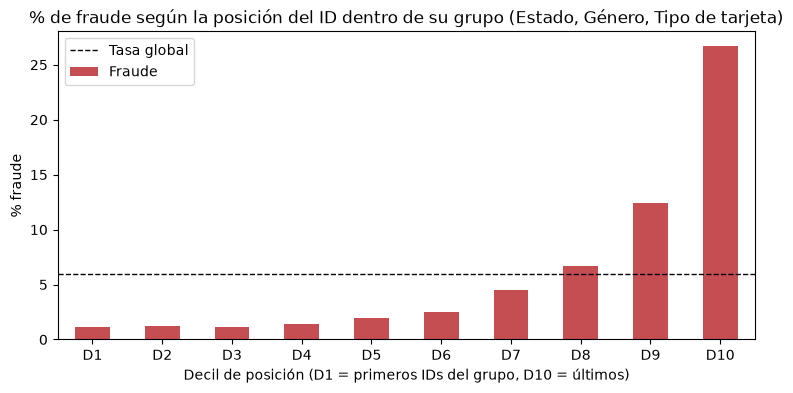

ID,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
% fraude,1.14,1.25,1.18,1.43,2.0,2.53,4.52,6.68,12.39,26.69


In [18]:
grupo = ["Estado","Genero","Tipo_Tarjeta"]
print("¿ID ordenado por Estado?", base["Estado"].is_monotonic_increasing)
pos = base.groupby(grupo)["ID"].rank(pct=True)
tasa_pos = base.groupby(pd.cut(pos, 10, labels=[f"D{i}" for i in range(1,11)]))["Fraude"].mean() * 100

plt.figure(figsize=(9,4))
tasa_pos.plot(kind="bar", color="#C44E52")
plt.axhline(100*base["Fraude"].mean(), color="black", ls="--", lw=1, label="Tasa global")
plt.title("% de fraude según la posición del ID dentro de su grupo (Estado, Género, Tipo de tarjeta)")
plt.xlabel("Decil de posición (D1 = primeros IDs del grupo, D10 = últimos)"); plt.ylabel("% fraude"); plt.legend(); plt.xticks(rotation=0)
plt.show()
tasa_pos.round(2).to_frame("% fraude").T

> **Interpretación:** en el primer decil la tasa de fraude es cercana al 1%, mientras que en el último supera el 25%. Esto **no es un comportamiento del cliente**: es un **artefacto del orden** en que se construyó el archivo (posiblemente estaba ordenado por alguna variable no publicada). En un sistema real de prevención de fraude esta información **no estaría disponible** para un cliente nuevo, así que usarla es una forma de **fuga de información (data leakage)**.
>
> **Decisión:** la base de modelamiento de este notebook **no incluye el ID**, para respetar la metodología de clase. En los notebooks de modelos se evaluará por separado su efecto en la AUC, y se discutirá en la presentación como **riesgo del modelo**.

## 4. Ingeniería de variables cuantitativas

Se construyen nuevas variables y cada una se evalúa con la **prueba de Kruskal-Wallis**, que compara la distribución de la variable entre fraudes y no fraudes ($H_0$: misma distribución). Se conservan como candidatas las que tienen **p valor ≤ 0.20** (criterio de clase).

> **Observación crítica:** con 848 mil registros las pruebas tienen muchísima potencia y casi cualquier diferencia, aunque sea mínima, resulta "significativa". Por eso el p valor solo sirve como **primer filtro**; la **selección final la hace XGBoost** por importancia (sección 6).

Igual que en los códigos de clase, las variables con valores mayores a 1000 (`Balance_Tj`) se dividen entre 1000 antes de elevar al cuadrado o multiplicar, para evitar números gigantes.

In [19]:
y_base = base["Fraude"].to_numpy()

def kruskal_p(x, y=y_base):
    # p valor de Kruskal-Wallis comparando la variable entre Fraude=1 y Fraude=0
    x = np.asarray(x, dtype=float)
    return stats.kruskal(x[y==1], x[y==0])[1]

# Variables que se escalan /1000 (decisión tomada con TRAIN y aplicada igual a TEST)
escalar = [k for k in cuantitativas if base[k].max() > 1000]
def esc(df, k):
    return df[k] / 1000 if k in escalar else df[k]
print("Variables escaladas /1000:", escalar)

Variables escaladas /1000: ['Balance_Tj']


### 4.1 Variables al cuadrado

In [20]:
base_cuadrado = pd.DataFrame(index=base.index)
var_names2, pvalue1 = [], []
for k in cuantitativas:
    base_cuadrado[k+"_2"] = esc(base,k) ** 2
    var_names2.append(k+"_2")
    pvalue1.append(kruskal_p(base_cuadrado[k+"_2"]))

pcuadrado1 = pd.DataFrame({"Variable":var_names2, "p value":pvalue1})
pcuadrado1

,Variable,p value
0,Num_Tarjetas_2,3.091874e-23
1,Balance_Tj_2,0.000000e+00
2,Total_Transac_2,0.000000e+00
3,Trans_Int_2,1.413620e-141


### 4.2 Interacciones cuantitativas ($X_i \cdot X_j$)

In [21]:
lista_inter = list(combinations(cuantitativas, 2))
print("Número de interacciones posibles:", len(lista_inter))

base_interacciones = pd.DataFrame(index=base.index)
var_interaccion, pv1 = [], []
for a, b in lista_inter:
    base_interacciones[a+"_"+b] = esc(base,a) * esc(base,b)
    var_interaccion.append(a+"_"+b)
    pv1.append(kruskal_p(base_interacciones[a+"_"+b]))

pxy = pd.DataFrame({"Variable":var_interaccion, "p value":pv1})
pxy

Número de interacciones posibles: 6


,Variable,p value
0,Num_Tarjetas_Balance_Tj,0.000000e+00
1,Num_Tarjetas_Total_Transac,0.000000e+00
2,Num_Tarjetas_Trans_Int,2.309664e-143
3,Balance_Tj_Total_Transac,0.000000e+00
4,Balance_Tj_Trans_Int,0.000000e+00
5,Total_Transac_Trans_Int,0.000000e+00


### 4.3 Razones ($X_i / (X_j + 0.01)$)
Se suma 0.01 al denominador para evitar divisiones por cero (por ejemplo, clientes con `Balance_Tj = 0`).

In [22]:
raz1 = [(x,y) for x in cuantitativas for y in cuantitativas if x != y]
print("Número de razones posibles:", len(raz1))

base_razones1 = pd.DataFrame(index=base.index)
var_nm, pval = [], []
for a, b in raz1:
    base_razones1[a+"_coc_"+b] = base[a] / (base[b] + 0.01)
    var_nm.append(a+"_coc_"+b)
    pval.append(kruskal_p(base_razones1[a+"_coc_"+b]))

prazones = pd.DataFrame({"Variable":var_nm, "p value":pval})
prazones

Número de razones posibles: 12


,Variable,p value
0,Num_Tarjetas_coc_Balance_Tj,0.000000e+00
1,Num_Tarjetas_coc_Total_Transac,0.000000e+00
2,Num_Tarjetas_coc_Trans_Int,2.156516e-125
3,Balance_Tj_coc_Num_Tarjetas,0.000000e+00
4,Balance_Tj_coc_Total_Transac,0.000000e+00
5,Balance_Tj_coc_Trans_Int,0.000000e+00
6,Total_Transac_coc_Num_Tarjetas,0.000000e+00
7,Total_Transac_coc_Balance_Tj,0.000000e+00
8,Total_Transac_coc_Trans_Int,0.000000e+00
9,Trans_Int_coc_Num_Tarjetas,3.724974e-139


## 5. Ingeniería de variables categóricas

### 5.1 Interacciones categóricas
Se concatenan dos categóricas (por ejemplo `Texas_Male`) y se evalúa su asociación con Fraude mediante **chi cuadrado**. Se registra también el número de modalidades, porque una interacción con muchas modalidades genera muchas columnas dummy.

In [23]:
cb = list(combinations(categoricas, 2))
p_value, modalidades, nombre_var = [], [], []

base2 = base.get(categoricas).copy()
for a, b in cb:
    base2[a+"_"+b] = base2[a] + "_" + base2[b]
    c1 = pd.crosstab(base["Fraude"], base2[a+"_"+b])
    p_value.append(stats.chi2_contingency(c1)[1])
    modalidades.append(base2[a+"_"+b].nunique())
    nombre_var.append(a+"_"+b)

pc = pd.DataFrame({"Variable":nombre_var, "Num Modalidades":modalidades, "p value":p_value})
pc

,Variable,Num Modalidades,p value
0,Estado_Genero,102,0.0
1,Estado_Tipo_Tarjeta,204,0.0
2,Genero_Tipo_Tarjeta,8,0.0


#### Base de modelamiento categórico (dummies de las interacciones con p valor ≤ 0.20)

In [24]:
seleccion1 = list(pc.loc[pc["p value"]<=0.20, "Variable"])

lb1 = pd.concat([pd.get_dummies(base2[k], prefix=k, prefix_sep="=", drop_first=True, dtype=np.uint8)
                 for k in seleccion1], axis=1)
print("Interacciones seleccionadas:", seleccion1)
print("Columnas dummy generadas:", lb1.shape[1])
lb1.iloc[:3, :8]

Interacciones seleccionadas: ['Estado_Genero', 'Estado_Tipo_Tarjeta', 'Genero_Tipo_Tarjeta']
Columnas dummy generadas: 311


,Estado_Genero=Alabama_Male,Estado_Genero=American Samoa_Female,Estado_Genero=American Samoa_Male,Estado_Genero=Arizona_Female,Estado_Genero=Arizona_Male,Estado_Genero=Arkansas_Female,Estado_Genero=Arkansas_Male,Estado_Genero=California_Female
0,1,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0


### 5.2 Interacción cuantitativa × categórica
Para cada par (cuantitativa, categórica) se crea la dummy de cada categoría y se multiplica por la variable numérica. Así la variable numérica puede tener un **efecto distinto según la categoría** (pendientes diferentes por grupo). Se evalúa cada columna con Kruskal y se guarda el **mínimo p valor** por par, como en los códigos de clase.

In [25]:
cat_cuanti = [(x,y) for x in cuantitativas for y in categoricas]
v1, v2, pvalores = [], [], []

for k1, k2 in cat_cuanti:
    g = pd.get_dummies(base[k2], dtype=np.uint8)
    pvalues_c = [kruskal_p(g[m] * base[k1]) for m in g.columns]
    v1.append(k1); v2.append(k2); pvalores.append(np.min(pvalues_c))

pc2 = pd.DataFrame({"Cuantitativa":v1, "Categórica":v2, "p value":pvalores})
pc2

,Cuantitativa,Categórica,p value
0,Num_Tarjetas,Estado,5.943539e-136
1,Num_Tarjetas,Genero,4.101165e-274
2,Num_Tarjetas,Tipo_Tarjeta,5.163557e-234
3,Balance_Tj,Estado,0.000000e+00
4,Balance_Tj,Genero,0.000000e+00
5,Balance_Tj,Tipo_Tarjeta,0.000000e+00
6,Total_Transac,Estado,1.732643e-194
7,Total_Transac,Genero,0.000000e+00
8,Total_Transac,Tipo_Tarjeta,0.000000e+00
9,Trans_Int,Estado,7.643750e-102


#### Base de modelamiento de interacciones cuantitativa × categórica (p valor ≤ 0.20)

In [26]:
sel2 = pc2.loc[pc2["p value"]<=0.20, ["Cuantitativa","Categórica"]].values.tolist()

bloques = []
for k1, k2 in sel2:
    g = pd.get_dummies(base[k2], drop_first=True, dtype=np.float32)
    g = g.mul(base[k1].astype(np.float32), axis=0)
    g.columns = [k1 + "_x_" + k2 + "=" + str(m) for m in g.columns]
    bloques.append(g)
g1 = pd.concat(bloques, axis=1)
print("Pares seleccionados:", len(sel2), "| columnas generadas:", g1.shape[1])
g1.iloc[:3, :6]

Pares seleccionados: 12 | columnas generadas: 216


,Num_Tarjetas_x_Estado=American Samoa,Num_Tarjetas_x_Estado=Arizona,Num_Tarjetas_x_Estado=Arkansas,Num_Tarjetas_x_Estado=California,Num_Tarjetas_x_Estado=Colorado,Num_Tarjetas_x_Estado=Connecticut
0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0


## 6. Selección de variables con XGBoost

Para cada grupo de variables nuevas se entrena un `XGBClassifier` y se ordenan las variables por **importancia** (normalizada al 100%). Se eligen las **3 más importantes de cada grupo**, igual que en los códigos de clase.

In [27]:
def importancia_xgb(X, y=y_base, titulo=""):
    t0 = time.time()
    modelo = XGBClassifier(n_estimators=100, tree_method="hist", n_jobs=-1, random_state=SEMILLA)
    modelo.fit(X, y)
    imp = pd.DataFrame({"Variable": X.columns, "Importancia": modelo.feature_importances_})
    imp["Importancia"] = imp["Importancia"] * 100 / imp["Importancia"].sum()
    imp = imp.sort_values("Importancia", ascending=False).reset_index(drop=True)

    top = imp.head(10).iloc[::-1]
    plt.figure(figsize=(8, 0.35*len(top)+1))
    plt.barh(top["Variable"], top["Importancia"], color=["#C44E52"]*3 + ["#4C72B0"]*(len(top)-3) if len(top)>3 else "#C44E52")
    plt.title(f"Importancia XGBoost — {titulo}"); plt.xlabel("% importancia")
    plt.show()
    print(f"({time.time()-t0:.1f} s)")
    return imp

### 6.1 Variables al cuadrado

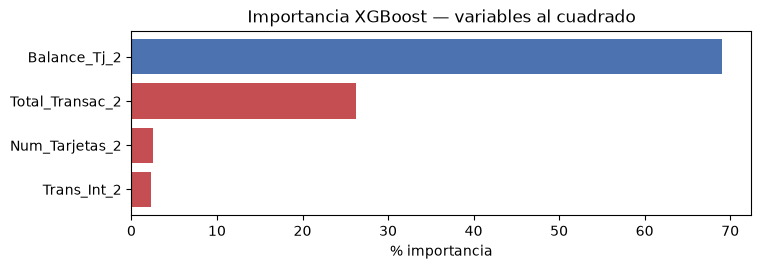

(0.8 s)


,Variable,Importancia
0,Balance_Tj_2,69.031265
1,Total_Transac_2,26.218235
2,Num_Tarjetas_2,2.481639
3,Trans_Int_2,2.268865


In [28]:
var_cuad = list(pcuadrado1.loc[pcuadrado1["p value"]<=0.20, "Variable"])
imp1 = importancia_xgb(base_cuadrado[var_cuad], titulo="variables al cuadrado")
imp1

### 6.2 Interacciones cuantitativas

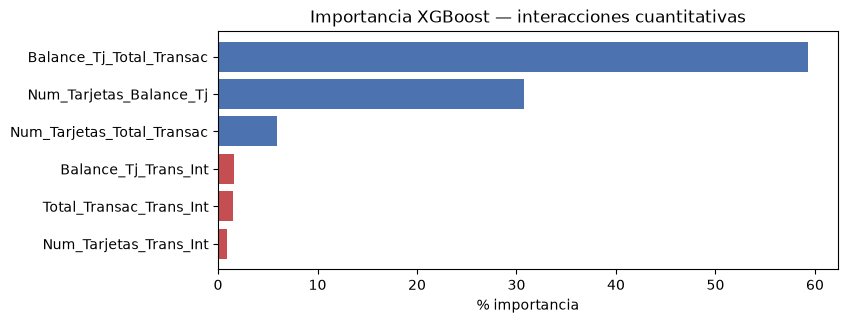

(0.7 s)


,Variable,Importancia
0,Balance_Tj_Total_Transac,59.350830
1,Num_Tarjetas_Balance_Tj,30.774672
2,Num_Tarjetas_Total_Transac,5.896958
3,Balance_Tj_Trans_Int,1.569273
4,Total_Transac_Trans_Int,1.541135
5,Num_Tarjetas_Trans_Int,0.867134


In [29]:
var_int = list(pxy.loc[pxy["p value"]<=0.20, "Variable"])
imp2 = importancia_xgb(base_interacciones[var_int], titulo="interacciones cuantitativas")
imp2

### 6.3 Razones

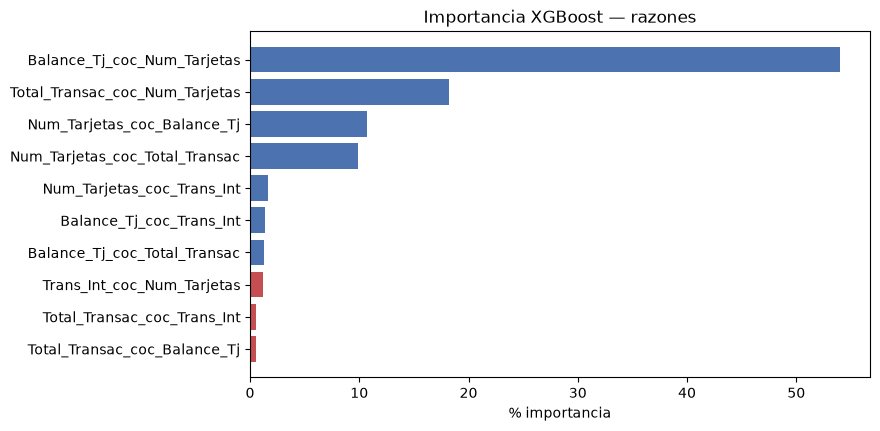

(0.9 s)


,Variable,Importancia
0,Balance_Tj_coc_Num_Tarjetas,54.046112
1,Total_Transac_coc_Num_Tarjetas,18.243132
2,Num_Tarjetas_coc_Balance_Tj,10.709618
3,Num_Tarjetas_coc_Total_Transac,9.857731
4,Num_Tarjetas_coc_Trans_Int,1.648651
5,Balance_Tj_coc_Trans_Int,1.386188
6,Balance_Tj_coc_Total_Transac,1.296971
7,Trans_Int_coc_Num_Tarjetas,1.218737
8,Total_Transac_coc_Trans_Int,0.584511
9,Total_Transac_coc_Balance_Tj,0.549598


In [30]:
var_raz = list(prazones.loc[prazones["p value"]<=0.20, "Variable"])
imp3 = importancia_xgb(base_razones1[var_raz], titulo="razones")
imp3.head(10)

### 6.4 Interacciones categóricas

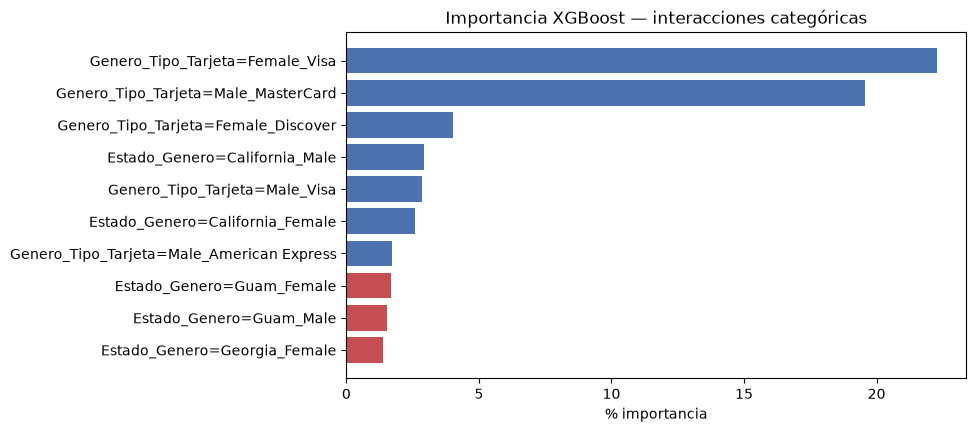

(3.8 s)


,Variable,Importancia
0,Genero_Tipo_Tarjeta=Female_Visa,22.273012
1,Genero_Tipo_Tarjeta=Male_MasterCard,19.544912
2,Genero_Tipo_Tarjeta=Female_Discover,4.012502
3,Estado_Genero=California_Male,2.915989
4,Genero_Tipo_Tarjeta=Male_Visa,2.868832
5,Estado_Genero=California_Female,2.594813
6,Genero_Tipo_Tarjeta=Male_American Express,1.702393
7,Estado_Genero=Guam_Female,1.686002
8,Estado_Genero=Guam_Male,1.541184
9,Estado_Genero=Georgia_Female,1.386276


In [31]:
imp4 = importancia_xgb(lb1, titulo="interacciones categóricas")
imp4.head(10)

### 6.5 Interacción cuantitativa × categórica

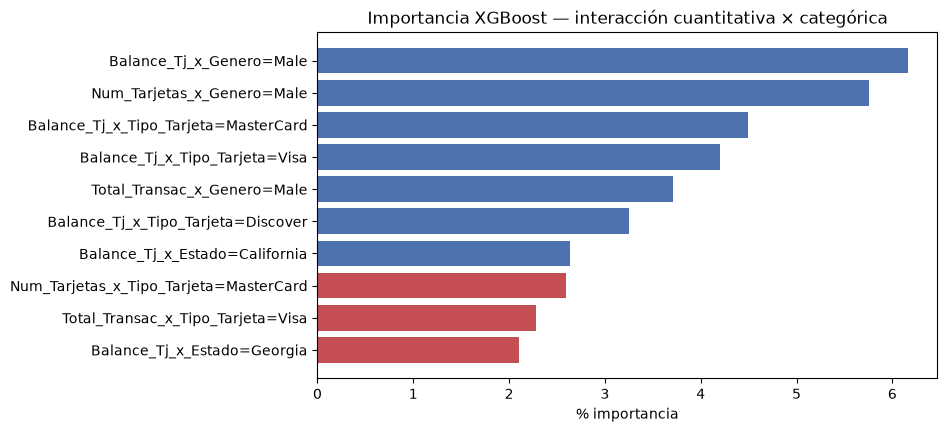

(7.7 s)


,Variable,Importancia
0,Balance_Tj_x_Genero=Male,6.162672
1,Num_Tarjetas_x_Genero=Male,5.756848
2,Balance_Tj_x_Tipo_Tarjeta=MasterCard,4.495726
3,Balance_Tj_x_Tipo_Tarjeta=Visa,4.199609
4,Total_Transac_x_Genero=Male,3.709949
5,Balance_Tj_x_Tipo_Tarjeta=Discover,3.255937
6,Balance_Tj_x_Estado=California,2.639126
7,Num_Tarjetas_x_Tipo_Tarjeta=MasterCard,2.593135
8,Total_Transac_x_Tipo_Tarjeta=Visa,2.283368
9,Balance_Tj_x_Estado=Georgia,2.106575


In [32]:
imp5 = importancia_xgb(g1, titulo="interacción cuantitativa × categórica")
imp5.head(10)

## 7. Mejores variables y construcción de la base de modelamiento

Se toman las **3 mejores de cada grupo**. En los grupos categóricos (6.4 y 6.5) se conservan solo las **3 columnas dummy más importantes**, no todas las modalidades de la interacción: esto mantiene el modelo **parsimonioso** (por ejemplo, `Estado_Tipo_Tarjeta` tiene más de 200 modalidades).

In [33]:
N_TOP = 3
c2      = list(imp1["Variable"].head(N_TOP))   # Variables al cuadrado
cxy     = list(imp2["Variable"].head(N_TOP))   # Interacciones cuantitativas
razxy   = list(imp3["Variable"].head(N_TOP))   # Razones
catxy   = list(imp4["Variable"].head(N_TOP))   # Interacciones categóricas (dummies)
cuactxy = list(imp5["Variable"].head(N_TOP))   # Interacción cuantitativa y categórica

mejores = pd.DataFrame({
    "Variables al cuadrado": c2, "Interacciones cuantitativas": cxy, "Razones": razxy,
    "Interacciones categóricas": catxy, "Cuantitativa × categórica": cuactxy})
mejores

,Variables al cuadrado,Interacciones cuantitativas,Razones,Interacciones categóricas,Cuantitativa × categórica
0,Balance_Tj_2,Balance_Tj_Total_Transac,Balance_Tj_coc_Num_Tarjetas,Genero_Tipo_Tarjeta=Female_Visa,Balance_Tj_x_Genero=Male
1,Total_Transac_2,Num_Tarjetas_Balance_Tj,Total_Transac_coc_Num_Tarjetas,Genero_Tipo_Tarjeta=Male_MasterCard,Num_Tarjetas_x_Genero=Male
2,Num_Tarjetas_2,Num_Tarjetas_Total_Transac,Num_Tarjetas_coc_Balance_Tj,Genero_Tipo_Tarjeta=Female_Discover,Balance_Tj_x_Tipo_Tarjeta=MasterCard


### Receta de transformaciones
En lugar de reescribir el código para test (como en los códigos de clase), las mejores variables se guardan como una **receta** y una sola función `construir_base()` la aplica igual a entrenamiento y a test. Esto garantiza que ambas bases tengan **exactamente las mismas columnas y transformaciones** (reproducibilidad).

In [34]:
receta = {
    "cuantitativas": cuantitativas,
    "categoricas": categoricas,
    "escalar": escalar,
    # variable al cuadrado -> variable original
    "cuadrados": {v: v[:-2] for v in c2},
    # interacción -> (a, b)
    "interacciones": {a+"_"+b: [a, b] for a, b in lista_inter if a+"_"+b in cxy},
    # razón -> (numerador, denominador)
    "razones": {a+"_coc_"+b: [a, b] for a, b in raz1 if a+"_coc_"+b in razxy},
    # dummy de interacción categórica -> (cat1, cat2, modalidad)
    "inter_categoricas": {v: [*[(a,b) for a,b in cb if v.startswith(a+"_"+b+"=")][0], v.split("=",1)[1]] for v in catxy},
    # cuantitativa x dummy de categoría -> (cuantitativa, categórica, modalidad)
    "cuanti_x_cat": {v: [v.split("_x_")[0], v.split("_x_")[1].split("=")[0], v.split("=",1)[1]] for v in cuactxy},
}

# Label Encoder ajustado SOLO con entrenamiento
Encoders = {k: LabelEncoder().fit(base[k]) for k in categoricas}

def construir_base(df):
    D = pd.DataFrame(index=df.index)
    # 1. Cuantitativas originales
    for k in receta["cuantitativas"]:
        D[k] = df[k]
    # 2. Categóricas originales en Label Encoder (transform, NO fit_transform)
    for k in receta["categoricas"]:
        D[k+"_LB"] = Encoders[k].transform(df[k])
    # 3. Mejores variables al cuadrado
    for v, k in receta["cuadrados"].items():
        D[v] = (df[k]/1000 if k in receta["escalar"] else df[k]) ** 2
    # 4. Mejores interacciones cuantitativas
    for v, (a, b) in receta["interacciones"].items():
        D[v] = (df[a]/1000 if a in receta["escalar"] else df[a]) * (df[b]/1000 if b in receta["escalar"] else df[b])
    # 5. Mejores razones
    for v, (a, b) in receta["razones"].items():
        D[v] = df[a] / (df[b] + 0.01)
    # 6. Mejores interacciones categóricas (dummy)
    for v, (a, b, m) in receta["inter_categoricas"].items():
        D[v] = ((df[a] + "_" + df[b]) == m).astype(np.uint8)
    # 7. Mejores interacciones cuantitativa x categórica
    for v, (k1, k2, m) in receta["cuanti_x_cat"].items():
        D[v] = (df[k2] == m).astype(np.uint8) * df[k1]
    return D

base_modelo = construir_base(base)
base_modelo["Fraude"] = base["Fraude"].values
base_modelo_prueba = construir_base(prueba)
base_modelo_prueba.insert(0, "ID", prueba["ID"].values)

print("Base modelo TRAIN:", base_modelo.shape, "(covariables + Fraude)")
print("Base modelo TEST: ", base_modelo_prueba.shape, "(ID + covariables)")
base_modelo.head(3)

Base modelo TRAIN: (848548, 23) (covariables + Fraude)
Base modelo TEST:  (200027, 23) (ID + covariables)


,Num_Tarjetas,Balance_Tj,Total_Transac,Trans_Int,Estado_LB,Genero_LB,Tipo_Tarjeta_LB,Balance_Tj_2,Total_Transac_2,Num_Tarjetas_2,Num_Tarjetas_Balance_Tj,Num_Tarjetas_Total_Transac,Balance_Tj_Total_Transac,Num_Tarjetas_coc_Balance_Tj,Balance_Tj_coc_Num_Tarjetas,Total_Transac_coc_Num_Tarjetas,Genero_Tipo_Tarjeta=Female_Visa,Genero_Tipo_Tarjeta=Male_MasterCard,Genero_Tipo_Tarjeta=Female_Discover,Balance_Tj_x_Genero=Male,Num_Tarjetas_x_Genero=Male,Balance_Tj_x_Tipo_Tarjeta=MasterCard,Fraude
0,1,2000,31,9,0,1,0,4.0,961,1,2.0,31,62.0,0.0005,1980.19802,30.693069,0,0,0,2000,1,0,0
1,1,0,25,0,0,1,0,0.0,625,1,0.0,25,0.0,100.0000,0.00000,24.752475,0,0,0,0,1,0,0
2,1,2000,78,3,0,1,0,4.0,6084,1,2.0,78,156.0,0.0005,1980.19802,77.227723,0,0,0,2000,1,0,0


### Validaciones de la base final

In [35]:
cov_train = [c for c in base_modelo.columns if c != "Fraude"]
cov_test  = [c for c in base_modelo_prueba.columns if c != "ID"]
assert cov_train == cov_test, "Las columnas de train y test no coinciden"
assert base_modelo.isnull().sum().sum() == 0 and base_modelo_prueba.isnull().sum().sum() == 0
assert np.isfinite(base_modelo[cov_train].to_numpy(dtype=float)).all()

# Verificación: las variables nuevas reconstruidas coinciden con las calculadas en la sección 4
for v in c2:    assert np.allclose(base_modelo[v], base_cuadrado[v])
for v in cxy:   assert np.allclose(base_modelo[v], base_interacciones[v])
for v in razxy: assert np.allclose(base_modelo[v], base_razones1[v])
for v in catxy: assert (base_modelo[v].values == lb1[v].values).all()
for v in cuactxy: assert np.allclose(base_modelo[v], g1[v])
print("✔ Train y test con las mismas", len(cov_train), "covariables, sin faltantes ni infinitos, y consistentes con la ingeniería de variables")

✔ Train y test con las mismas 22 covariables, sin faltantes ni infinitos, y consistentes con la ingeniería de variables


### Correlación de la base de modelamiento

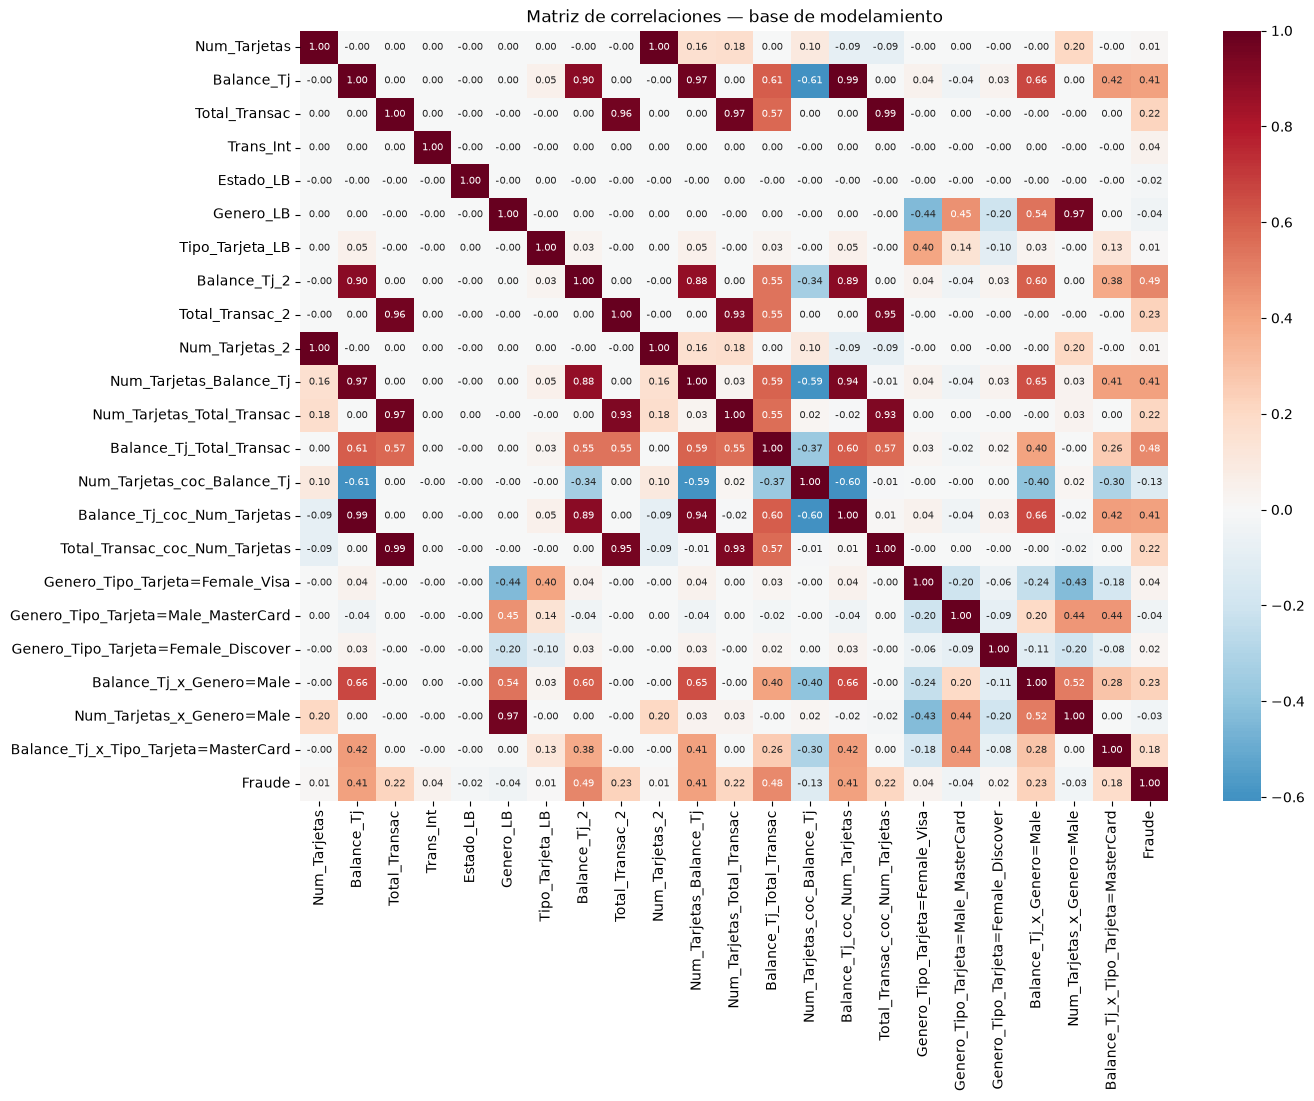

In [36]:
plt.figure(figsize=(14,10))
sns.heatmap(base_modelo.corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size":7})
plt.title("Matriz de correlaciones — base de modelamiento"); plt.show()

## 8. Guardar artefactos para los notebooks de modelos

In [37]:
base_modelo.to_parquet(OUT_DIR + "base_modelo_train.parquet", index=False)
base_modelo_prueba.to_parquet(OUT_DIR + "base_modelo_test.parquet", index=False)
with open(OUT_DIR + "receta_variables.json", "w", encoding="utf-8") as f:
    json.dump(receta, f, ensure_ascii=False, indent=2)
print(os.listdir(OUT_DIR))

['modelo_logistica_no_balanceo.pkl', 'base_modelo_train.parquet', 'modelo_rforest_balanceo.pkl', 'resultados_rforest.json', 'modelo_ensamble_no_balanceo.pkl', 'resultados_xgboost.json', 'base_modelo_test.parquet', 'modelo_logistica_balanceo.pkl', 'modelo_xgboost_balanceo.pkl', 'resultados_logistica.json', 'modelo_ensamble_balanceo.pkl', 'receta_variables.json', 'modelo_rforest_no_balanceo.pkl', 'modelo_xgboost_no_balanceo.pkl', 'resultados_ensamble.json']


## 9. Conclusiones de la exploración

1. **Calidad de datos:** 848,548 clientes en entrenamiento y 200,027 en test, **sin datos faltantes**, sin IDs repetidos y sin categorías nuevas en test. No fue necesario imputar.
2. **Desbalance:** solo el **6.0%** de los clientes cometió fraude. Por eso el *accuracy* no sirve como métrica (un modelo que diga siempre "no fraude" acertaría el 94%) y se usa la **AUC-ROC**; además se probará **balanceo de clases** (SMOTE + undersampling) en los modelos.
3. **Perfil del fraude:** los clientes fraudulentos tienen un **balance en tarjetas casi 3 veces mayor** (mediana 10,593 vs 3,140) y **más del doble de transacciones** (mediana 47 vs 19). `Num_Tarjetas` y `Trans_Int` diferencian poco.
4. **Categóricas:** la tasa de fraude es mayor en **mujeres** (7.1% vs 5.3%), en tarjetas **Visa y Discover** (≈7%) frente a MasterCard (4.9%), y varía entre estados (de 3.9% a 8.7%). Las tres categóricas están asociadas con Fraude (chi cuadrado, p < 0.001).
5. **Pruebas de hipótesis:** con este tamaño de muestra casi todas las variables construidas resultan significativas (p ≈ 0); solo la razón `Trans_Int / Total_Transac` no pasó el filtro (p = 0.52). Por eso la **selección por importancia de XGBoost** es la que realmente discrimina.
6. **Variables seleccionadas:** dominan las construidas con **`Balance_Tj` y `Total_Transac`** (su cuadrado, su producto y su relación con el número de tarjetas), y las combinaciones **género × tipo de tarjeta**. La base final tiene **22 covariables** (7 originales + 15 nuevas).
7. **Ruido irreducible:** 38.8% de los registros comparten exactamente las mismas características con otro cliente, y 27,840 filas tienen perfiles idénticos con etiquetas distintas (fraude y no fraude). Ningún modelo puede separarlos, lo que pone un **techo** a la AUC alcanzable con estas variables.
8. **Riesgo identificado:** el orden del `ID` contiene información del fraude (artefacto de construcción del archivo). Se analizará de forma transparente en los notebooks de modelos.

**Siguiente paso:** notebooks 02 a 05, donde se entrenan Regresión Logística, Random Forest, XGBoost y el Ensamble sobre `base_modelo_train.parquet`.